# Base de Dados para Modelo de Recomendação - Aventura Teatros

## 1. Introdução

O Portal Aventura atualmente não possui um sistema estruturado de recomendação de espetáculos. Isso faz com que visitantes acessem uma página de um espetáculo sem receber sugestões de outras experiências relevantes, reduzindo a descoberta de conteúdo e a conversão em vendas.

Este notebook tem como objetivo estruturar e preparar a base de dados que alimentará o modelo de **filtragem colaborativa**. Nessa abordagem, as recomendações são geradas com base no padrão de avaliações de usuários com perfis semelhantes, ou seja, se dois usuários avaliaram positivamente espetáculos parecidos no passado, o sistema recomenda ao primeiro o que o segundo também gostou.

## 1.1 Estratégias de Formatação do CSV

A base inicial fornecida passou por um processo de tratamento e enriquecimento com o objetivo de torná-la adequada para uso em etapas posteriores do projeto, especialmente no contexto de modelagem e recomendação.

### Base inicial (remoção de colunas irrelevantes)
A planilha original foi utilizada como ponto de partida, contendo diversas informações relacionadas às compras de ingressos. Entretanto, nem todas as colunas eram relevantes para o escopo do projeto. Dessa forma, foram removidas colunas como *método de pagamento* e *canal da venda*, por não contribuírem diretamente para a lógica de recomendação ou análise de conteúdo. Essa etapa teve como foco reduzir ruído, simplificar a estrutura dos dados e manter apenas informações pertinentes ao comportamento do usuário e às características dos espetáculos.

### Avaliação (população sintética com distribuição controlada)
Foi criada e populada a coluna avaliacao, inexistente na base original, com o objetivo de simular feedback dos usuários. Para isso, utilizou-se uma abordagem probabilística com a biblioteca numpy, gerando valores inteiros de 1 a 5. A distribuição foi intencionalmente enviesada, atribuindo maior probabilidade às notas 3 e 4, de forma a refletir um cenário mais realista, em que avaliações intermediárias são mais frequentes do que extremos. Essa estratégia permite enriquecer a base para testes de algoritmos que dependem de interações explícitas, como sistemas de recomendação baseados em rating.

```
import pandas as pd
import numpy as np

df = pd.read_csv("base_tratada.csv")

df["avaliacao"] = np.random.choice(
    [1, 2, 3, 4, 5],
    size=len(df),
    p=(np.array([0.1, 0.15, 0.35, 0.25, 0.1]) / np.sum([0.1, 0.15, 0.35, 0.25, 0.1]))
)

df.to_csv("base_com_avaliacao.csv", index=False)
```

### Produção (enriquecimento por cruzamento de bases)
A coluna tipo_producao foi preenchida a partir do cruzamento entre a base principal e uma planilha auxiliar posteriormente fornecida contendo informações sobre os espetáculos (incluindo o tipo de produção, como externa, companhia ou corporativa). Esse processo foi realizado por meio de um merge utilizando a biblioteca pandas, tendo como chave o nome do espetáculo (nome_evento na base principal e nome_espetaculo na base auxiliar).

Antes do cruzamento, foi realizada uma padronização textual (remoção de espaços e conversão para minúsculas) para garantir maior taxa de correspondência entre os registros. Como resultado, a base final passou a incorporar informações adicionais relevantes sobre cada espetáculo, enriquecendo o contexto dos dados e possibilitando análises mais completas e segmentadas.

```
import pandas as pd

# carregar bases
df1 = pd.read_csv("base_com_avaliacao.csv", sep=";", encoding="latin1")
df2 = pd.read_csv("base_espetaculos.csv", sep=";", encoding="latin1")

# padronizar colunas
df1.columns = df1.columns.str.strip().str.lower()
df2.columns = df2.columns.str.strip().str.lower()

# padronizar valores para matching
df1["nome_evento"] = df1["nome_evento"].str.strip().str.lower()
df2["nome_espetaculo"] = df2["nome_espetaculo"].str.strip().str.lower()

# merge
df_final = df1.merge(
    df2,
    how="left",
    left_on="nome_evento",
    right_on="nome_espetaculo"
)

# preencher tipo de produção
df_final["tipo_producao"] = df_final["producao"]

# limpar colunas auxiliares
df_final = df_final.drop(columns=["nome_espetaculo", "producao"])

# salvar resultado final
df_final.to_csv("base_final.csv", index=False)

print("Arquivo gerado com sucesso!")
```


## 2. Carregamento do Dataset

In [72]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Estilo de visualização
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 5)

# Carregamento
df = pd.read_csv('../dataset/recomendacao.csv')
df = df.rename(columns={'evento': 'nome_evento'})
if 'tipo_producao' not in df.columns:
    df['tipo_producao'] = 'Nao informado'
print(f'Dataset carregado com sucesso!')
print(f'   Registros: {len(df):,}')
print(f'   Colunas:   {df.shape[1]}')
df.head()


 Dataset carregado com sucesso!
   Registros: 343,974
   Colunas:   10


,id_user,nome_evento,teatro,data_da_apresentacao,data_da_compra,setor,valor_do_ingresso,tipo_producao,categoria,avaliacao
0,1,um mallandro na quarentena com sergio mallandro,TEATRO RIACHUELO RJ,6/26/21 20:00,5/20/21 5:03,PLATEIA VIP - 02 PESSOAS,120,EXTERNA,Show Stand-Up,3
1,1,um mallandro na quarentena com sergio mallandro,TEATRO RIACHUELO RJ,6/26/21 20:00,5/20/21 5:03,PLATEIA VIP - 02 PESSOAS,120,EXTERNA,Show Stand-Up,4
2,2,dominguinhos - isso aqui tá bom demais,TEATRO RIACHUELO RJ,6/9/23 20:00,6/9/23 10:04,BALCÃO,50,EXTERNA,Show Musical,5
3,2,dominguinhos - isso aqui tá bom demais,TEATRO RIACHUELO RJ,6/9/23 20:00,6/9/23 10:04,BALCÃO,50,EXTERNA,Show Musical,3
4,3,a noviça rebelde,TEATRO RIACHUELO RJ,5/11/24 19:00,5/10/24 20:33,PLATEIA,225,AVENTURA,Espetáculo Musical,3


## 3. Descrição do Dataset

In [73]:
print('=== Informações Gerais do Dataset ===') 
print(f'Registros totais       : {len(df):>10,}')
print(f'Usuários únicos        : {df["id_user"].nunique():>10,}')
print(f'Espetáculos únicos     : {df["nome_evento"].nunique():>10,}')
print(f'Teatros únicos         : {df["teatro"].nunique():>10,}')
print(f'Categorias únicas      : {df["categoria"].nunique():>10,}')
print('\nColunas disponíveis:')
for col in df.columns:
    print(f'  - {col} ({df[col].dtype})')
print()
print('=== Tipos e Nulos ===')    
print(df.dtypes)
print()
print('Valores nulos por coluna:')
print(df.isnull().sum())


=== Informações Gerais do Dataset ===
Registros totais       :    343,974
Usuários únicos        :     68,564
Espetáculos únicos     :        571
Teatros únicos         :          4
Categorias únicas      :          8

Colunas disponíveis:
  - id_user (int64)
  - nome_evento (str)
  - teatro (str)
  - data_da_apresentacao (str)
  - data_da_compra (str)
  - setor (str)
  - valor_do_ingresso (str)
  - tipo_producao (str)
  - categoria (str)
  - avaliacao (int64)

=== Tipos e Nulos ===
id_user                 int64
nome_evento               str
teatro                    str
data_da_apresentacao      str
data_da_compra            str
setor                     str
valor_do_ingresso         str
tipo_producao             str
categoria                 str
avaliacao               int64
dtype: object

Valores nulos por coluna:
id_user                 0
nome_evento             0
teatro                  0
data_da_apresentacao    1
data_da_compra          1
setor                   1
valor_do_ingres

In [74]:
print('Estatísticas descritivas das avaliações:')
df[['avaliacao']].describe().round(2)

Estatísticas descritivas das avaliações:


,avaliacao
count,343974.00
mean,3.10
std,1.12
min,1.00
25%,2.00
50%,3.00
75%,4.00
max,5.00


In [75]:
print('Interações por usuário:')
user_counts = df.groupby('id_user').size()
display(user_counts.describe().rename('interações').to_frame())

print('\nInterações por espetáculo:')
item_counts = df.groupby('nome_evento').size()
display(item_counts.describe().rename('interações').to_frame())

Interações por usuário:


,interações
count,68564.000000
mean,5.016831
std,304.622645
min,1.000000
25%,2.000000
50%,2.000000
75%,4.000000
max,79721.000000



Interações por espetáculo:


,interações
count,571.000000
mean,602.406305
std,1916.956592
min,1.000000
25%,63.500000
50%,154.000000
75%,402.000000
max,32475.000000


## 4. Análise do Balanceamento do Dataset

Antes de aplicar qualquer transformação, analisamos a distribuição bruta dos dados para identificar os principais problemas de balanceamento

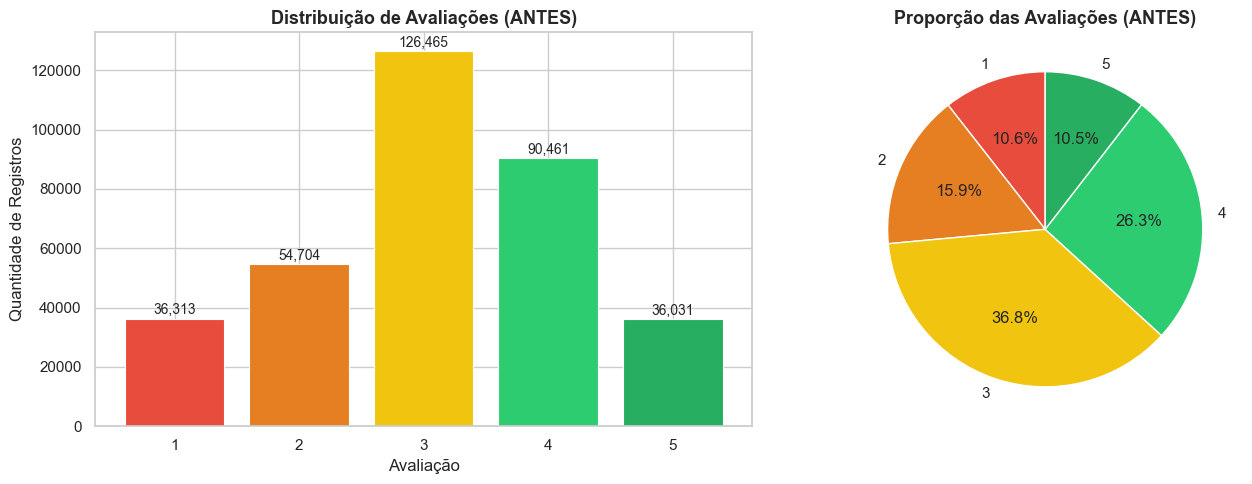

 Avaliação 3 domina 36.8% dos registros = dataset desbalanceado


In [76]:
# Distribuição das avaliações (ANTES)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

rating_counts = df['avaliacao'].value_counts().sort_index()

# Barras
bars = axes[0].bar(rating_counts.index, rating_counts.values,
                   color=['#e74c3c','#e67e22','#f1c40f','#2ecc71','#27ae60'],
                   edgecolor='white', linewidth=0.8)
axes[0].set_title('Distribuição de Avaliações (ANTES)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Avaliação')
axes[0].set_ylabel('Quantidade de Registros')
for bar, val in zip(bars, rating_counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 500,
                 f'{val:,}', ha='center', va='bottom', fontsize=10)

# Pizza
pct = rating_counts / rating_counts.sum() * 100
axes[1].pie(pct, labels=[f'{i}' for i in rating_counts.index],
            autopct='%1.1f%%', colors=['#e74c3c','#e67e22','#f1c40f','#2ecc71','#27ae60'],
            startangle=90)
axes[1].set_title('Proporção das Avaliações (ANTES)', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()
print(f' Avaliação 3 domina {pct[3]:.1f}% dos registros = dataset desbalanceado')

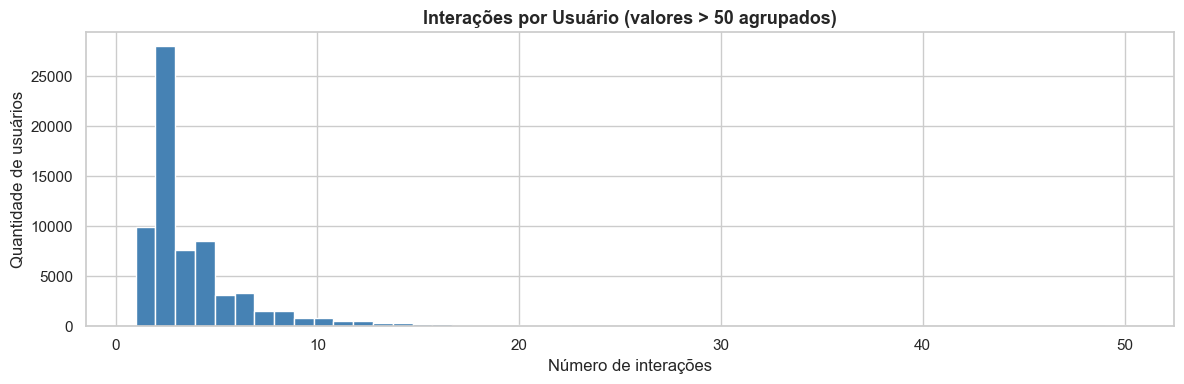

 Usuário outlier: ID 68564 com 79,721 interações
   Mediana de interações por usuário: 2
   Usuários com apenas 1 interação: 9,883


In [77]:
# Distribuição de interações por usuário
fig, ax = plt.subplots(figsize=(12, 4))
clipped = user_counts.clip(upper=50) # Limitar para visualização
ax.hist(clipped, bins=50, color='steelblue', edgecolor='white')
ax.set_title('Interações por Usuário (valores > 50 agrupados)', fontsize=13, fontweight='bold')
ax.set_xlabel('Número de interações')
ax.set_ylabel('Quantidade de usuários')
plt.tight_layout()
plt.show()

outlier_user = user_counts.idxmax()
print(f' Usuário outlier: ID {outlier_user} com {user_counts.max():,} interações')
print(f'   Mediana de interações por usuário: {user_counts.median():.0f}')
print(f'   Usuários com apenas 1 interação: {(user_counts == 1).sum():,}')

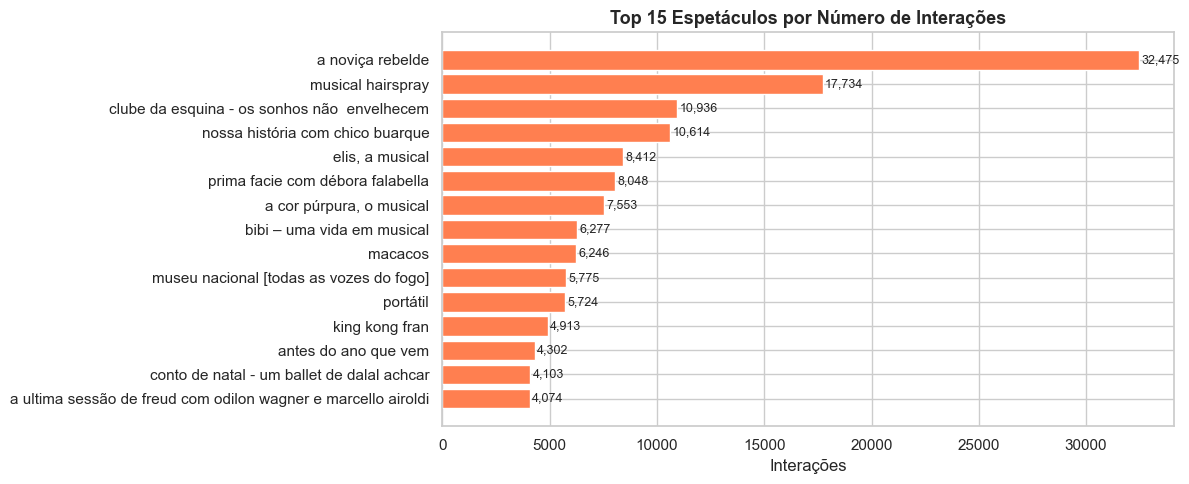

In [78]:
# Top 15 espetáculos mais avaliados
top_items = item_counts.sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.barh(top_items.index[::-1], top_items.values[::-1], color='coral', edgecolor='white')
ax.set_title('Top 15 Espetáculos por Número de Interações', fontsize=13, fontweight='bold')
ax.set_xlabel('Interações')
for bar, val in zip(bars, top_items.values[::-1]):
    ax.text(bar.get_width() + 100, bar.get_y() + bar.get_height()/2,
            f'{val:,}', va='center', fontsize=9)
plt.tight_layout()
plt.show()

### 4.1 Balanceamento - Passo a Passo

Aplicaremos as seguintes etapas:

| Passo | Ação | Justificativa |
|---|---|---|
| 1 | Agregar duplicatas (média por par user-item) | Elimina múltiplas avaliações do mesmo par |
| 2 | Remover usuário outlier extremo | Usuário com 79k registros distorce o modelo |
| 3 | Filtrar cold start de usuários (< 3 interações) | Usuários raros não geram padrões aprendíveis |
| 4 | Filtrar cold start de itens (< 10 interações) | Itens raros não recebem recomendações |
| 5 | Balancear distribuição de ratings | Reduz viés para nota 3 via undersampling |



In [ ]:

df = df.copy()

df_agg = (
    df.groupby(['id_user', 'nome_evento'], as_index=False)
      .agg(avaliacao=('avaliacao', 'mean'),
           categoria=('categoria', 'first'),
           tipo_producao=('tipo_producao', 'first'),
           teatro=('teatro', 'first'))
)

# Arredondar para valor inteiro mais próximo
df_agg['avaliacao'] = df_agg['avaliacao'].round().astype(int)

print(f'Registros antes da agregação : {len(df):>10,}')
print(f'Registros após agregação      : {len(df_agg):>10,}')
print(f'Redução                       : {len(df) - len(df_agg):>10,} registros')



In [ ]:
# Remover usuário outlier extremo
user_freq = df_agg.groupby('id_user').size()

# Remover usuários com mais de 500 interações (outlier extremo)
MAX_USER_INTERACTIONS = 500
valid_users = user_freq[user_freq <= MAX_USER_INTERACTIONS].index

df_agg = df_agg[df_agg['id_user'].isin(valid_users)]

removed = (~df_agg['id_user'].isin(valid_users)).sum()
print(f'Usuários outlier removidos    : {(user_freq > MAX_USER_INTERACTIONS).sum()}')
print(f'Registros após remoção outlier: {len(df_agg):>10,}')



In [ ]:
# Filtrar cold start de usuários (mínimo 3 interações) 
MIN_USER_INTERACTIONS = 3

user_freq2 = df_agg.groupby('id_user').size()
valid_users2 = user_freq2[user_freq2 >= MIN_USER_INTERACTIONS].index
df_agg = df_agg[df_agg['id_user'].isin(valid_users2)]

print(f'Usuários cold-start removidos : {(user_freq2 < MIN_USER_INTERACTIONS).sum():>10,}')
print(f'Registros após filtro usuário : {len(df_agg):>10,}')

In [ ]:
# Filtrar cold start de itens (mínimo 10 interações)
MIN_ITEM_INTERACTIONS = 10

item_freq = df_agg.groupby('nome_evento').size()
valid_items = item_freq[item_freq >= MIN_ITEM_INTERACTIONS].index
df_agg = df_agg[df_agg['nome_evento'].isin(valid_items)]

print(f'Itens cold-start removidos    : {(item_freq < MIN_ITEM_INTERACTIONS).sum():>10,}')
print(f'Registros após filtro item    : {len(df_agg):>10,}')
print(f'Espetáculos restantes         : {df_agg["nome_evento"].nunique():>10,}')

In [ ]:
# Balancear distribuição de ratings via undersampling
# A avaliação 3 (neutra) domina. Vamos limitar ao dobro da menor classe

rating_dist = df_agg['avaliacao'].value_counts().sort_index()
min_class = rating_dist.min()
target_size = min(min_class * 2, rating_dist.max())  # 2x a menor classe

print('Distribuição antes do undersampling:')
print(rating_dist.to_string())
print(f'\nLimite por classe: {target_size:,}')

balanced_parts = []
for rating_val, group in df_agg.groupby('avaliacao'):
    if len(group) > target_size:
        group = group.sample(n=target_size, random_state=42)
    balanced_parts.append(group)

df_balanced = pd.concat(balanced_parts).sample(frac=1, random_state=42).reset_index(drop=True)

print('\nDistribuição APÓS undersampling:')
print(df_balanced['avaliacao'].value_counts().sort_index().to_string())


In [ ]:
# criar IDs numéricos para user e item
user_map = {u: i for i, u in enumerate(df_balanced['id_user'].unique())}
item_map = {e: i for i, e in enumerate(df_balanced['nome_evento'].unique())}

df_balanced['user_id'] = df_balanced['id_user'].map(user_map)
df_balanced['item_id'] = df_balanced['nome_evento'].map(item_map)
df_balanced['rating']  = df_balanced['avaliacao'].astype(float)

print(f'Usuários únicos no dataset final : {df_balanced["user_id"].nunique():>8,}')
print(f'Espetáculos únicos no dataset    : {df_balanced["item_id"].nunique():>8,}')
print(f'Registros totais                  : {len(df_balanced):>8,}')
df_balanced[['user_id','item_id','rating','nome_evento','categoria','tipo_producao']].head(10)


In [ ]:
# Visualização comparativa ANTES x DEPOIS 
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colors = ['#e74c3c','#e67e22','#f1c40f','#2ecc71','#27ae60']

# ANTES
before = df['avaliacao'].value_counts().sort_index()
axes[0].bar(before.index, before.values, color=colors, edgecolor='white')
axes[0].set_title('Distribuição de Ratings - ANTES', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Avaliação'); axes[0].set_ylabel('Registros')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))

# DEPOIS
after = df_balanced['avaliacao'].value_counts().sort_index()
axes[1].bar(after.index, after.values, color=colors, edgecolor='white')
axes[1].set_title('Distribuição de Ratings - DEPOIS', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Avaliação'); axes[1].set_ylabel('Registros')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))

plt.suptitle('Efeito do Balanceamento no Dataset', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()


In [ ]:
# Esparsidade da matriz user-item
n_users = df_balanced['user_id'].nunique()
n_items = df_balanced['item_id'].nunique()
n_interactions = len(df_balanced)
sparsity = 1 - (n_interactions / (n_users * n_items))

print(f'Matriz user-item: {n_users:,} x {n_items:,}')
print(f'Interações preenchidas: {n_interactions:,}')
print(f'Esparsidade da matriz: {sparsity:.4%}')

# Distribuição final de interações por usuário
fig, ax = plt.subplots(figsize=(10, 4))
df_balanced.groupby('user_id').size().hist(bins=40, ax=ax, color='steelblue', edgecolor='white')
ax.set_title('Interações por Usuário - Dataset Balanceado', fontsize=13, fontweight='bold')
ax.set_xlabel('Número de interações')
ax.set_ylabel('Número de usuários')
plt.tight_layout()
plt.show()


In [ ]:
# Salvar dataset final
# Arquivo principal para o modelo (Spotlight)
df_final = df_balanced[['user_id', 'item_id', 'rating']]
df_final.to_csv('../dataset/recomendacao_balanceado.csv', index=False)

# Arquivo auxiliar com metadados dos itens (útil para exibir nomes nas recomendações)
item_meta = (df_balanced[['item_id','nome_evento','categoria','tipo_producao']]
             .drop_duplicates('item_id')
             .sort_values('item_id'))
item_meta.to_csv('../dataset/itens_metadata.csv', index=False)

print('Arquivos salvos com sucesso!')
print(f'   recomendacao_balanceado.csv  -> {len(df_final):,} registros')
print(f'   itens_metadata.csv           -> {len(item_meta):,} espetáculos')
df_final.head()


## 5. Conclusão. 
    
### Descobertas Principais

A análise exploratória revelou um dataset rico, porém com problemas de qualidade que precisavam ser tratados antes de alimentar o modelo de filtragem colaborativa:

1. **Outlier crítico**: O usuário de ID `68564` concentrava ~79.505 registros - cerca de 23% do dataset inteiro. Esse volume é incompatível com comportamento humano normal e foi removido.

2. **Duplicatas por (usuário, evento)**: Múltiplos registros do mesmo par usuário-evento (máximo: 5.326 para o mesmo par) foram agregados em uma única avaliação média, evitando que usuários muito ativos distorcessem os padrões do modelo.

3. **Desequilíbrio de avaliações**: No dataset bruto, a nota 3 representava 37% dos registros enquanto notas extremas (1 e 5) somavam apenas 21%. Após o balanceamento via undersampling, a distribuição foi equalizada, permitindo ao modelo aprender igualmente bem os padrões de usuários insatisfeitos e satisfeitos.

4. **Usuários cold-start**: Usuários com menos de 3 interações foram removidos, pois a filtragem colaborativa não consegue gerar recomendações confiáveis sem um histórico mínimo.

### Dataset Final

| Métrica | Valor |
|---|---|
| Total de registros (bruto) | 343.758 |
| Usuários únicos | 68.564 |
| Eventos únicos | 571 |
| Registros após balanceamento | 10.745 |

### Próximos Passos

1. **Codificação dos IDs**: Transformar `id_user` e `nome_evento` em índices inteiros contínuos para uso na matriz usuário-item;
2. **Divisão treino/teste**: Separar os dados em splits estratificados por usuário para avaliação justa do modelo;
3. **Implementação do modelo**: Experimentar algoritmos de filtragem colaborativa (ex.: SVD, NMF, KNN baseado em usuário/item) com a biblioteca `Surprise` ou `LightFM`;
4. **Avaliação de métricas**: Medir a qualidade das recomendações com RMSE, MAE e Precision@K;
5. **Integração com o Portal Aventura**: Expor as recomendações via API REST para consumo pelo front-end do portal.
  